In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

project = Path(r"C:\Users\redhu\OneDrive\Desktop\Bearing_fault_detection")
registry = pd.read_csv(project / "metadata/window_registry.csv")

row = registry.iloc[0]
windows = np.load(project / row["window_file"])

print("Recording:", row["recording_id"])
print("Windows shape:", windows.shape)

Recording: N09_M07_F10_K001_2
Windows shape: (4, 64000)


In [3]:
rms = np.sqrt(np.mean(windows**2, axis=1))
print("RMS per window:", rms)

RMS per window: [0.36638836 0.36392978 0.36853306 0.36145133]


In [4]:
peak = np.max(np.abs(windows), axis=1)
assert (rms > 0).all(), "Crest factor is undefined when RMS is zero."
crest_factor = peak / rms

print("Crest factor per window:", crest_factor)

Crest factor per window: [10.38787119 11.27742394 12.22899021 13.45848449]


In [5]:
from scipy.stats import kurtosis

pearson_kurtosis = kurtosis(windows, axis=1, fisher=False)
print("Pearson kurtosis per window:", pearson_kurtosis)

Pearson kurtosis per window: [18.86923963 19.60466856 19.74965252 20.01581663]


In [6]:
features = registry[
    registry["recording_id"].eq(row["recording_id"])
].sort_values("window_no").copy()

assert len(features) == len(windows), "Check window metadata."
features["RMS"] = rms
features["Crest factor"] = crest_factor
features["Pearson kurtosis"] = pearson_kurtosis

features[["recording_id", "window_no", "RMS", "Crest factor", "Pearson kurtosis"]]

,recording_id,window_no,RMS,Crest factor,Pearson kurtosis
0,N09_M07_F10_K001_2,0,0.366388,10.387871,18.869240
1,N09_M07_F10_K001_2,1,0.363930,11.277424,19.604669
2,N09_M07_F10_K001_2,2,0.368533,12.228990,19.749653
3,N09_M07_F10_K001_2,3,0.361451,13.458484,20.015817


In [7]:
from scipy.signal import welch

fs = float(row["nominal_fs_hz"])
frequency, psd = welch(
    windows, fs=fs, window="hann",
    nperseg=8192, noverlap=4096, axis=1
)

print("PSD shape:", psd.shape)

PSD shape: (4, 4097)


In [8]:
band = (frequency >= 0) & (frequency <= 2000)

features["0-2000 Hz power"] = np.trapezoid(
    psd[:, band], x=frequency[band], axis=1
)

features[["window_no", "0-2000 Hz power"]]

,window_no,0-2000 Hz power
0,0,0.008511
1,1,0.009116
2,2,0.008149
3,3,0.008461


In [9]:
total_power = np.trapezoid(psd, x=frequency, axis=1)
assert (total_power > 0).all(), "Relative power needs positive total power."

features["0-2000 Hz share (%)"] = 100 * features["0-2000 Hz power"] / total_power

features[["window_no", "0-2000 Hz power", "0-2000 Hz share (%)"]]

,window_no,0-2000 Hz power,0-2000 Hz share (%)
0,0,0.008511,6.317819
1,1,0.009116,6.858693
2,2,0.008149,6.117246
3,3,0.008461,6.469498


In [10]:
bands = [(2000, 5000), (5000, 12000), (12000, fs / 2)]

for low, high in bands:
    band = (frequency >= low) & (frequency <= high)
    power = np.trapezoid(psd[:, band], x=frequency[band], axis=1)
    name = f"{low:g}-{high:g} Hz"
    features[f"{name} power"] = power
    features[f"{name} share (%)"] = 100 * power / total_power

features.filter(like="Hz")

,0-2000 Hz power,0-2000 Hz share (%),2000-5000 Hz power,2000-5000 Hz share (%),5000-12000 Hz power,5000-12000 Hz share (%),12000-32000 Hz power,12000-32000 Hz share (%)
0,0.008511,6.317819,0.014262,10.586618,0.030819,22.877667,0.081122,60.217896
1,0.009116,6.858693,0.013942,10.489546,0.029976,22.553961,0.079875,60.097800
2,0.008149,6.117246,0.014143,10.616736,0.031268,23.471637,0.079656,59.794380
3,0.008461,6.469498,0.013019,9.954644,0.030873,23.606267,0.078431,59.969591


In [11]:
features["Spectral centroid (Hz)"] = np.trapezoid(
    psd * frequency, x=frequency, axis=1
) / total_power

features[["window_no", "Spectral centroid (Hz)"]]

,window_no,Spectral centroid (Hz)
0,0,15528.341188
1,1,15548.881778
2,2,15612.403115
3,3,15555.172930


In [12]:
peak_index = np.argmax(psd[:, 1:], axis=1) + 1
features["Dominant frequency (Hz)"] = frequency[peak_index]

features[["window_no", "Dominant frequency (Hz)"]]

,window_no,Dominant frequency (Hz)
0,0,3265.6250
1,1,3273.4375
2,2,3257.8125
3,3,3265.6250


In [13]:
feature_values = features.drop(columns=registry.columns)

assert np.isfinite(feature_values.to_numpy()).all(), "Invalid feature values."
print("Windows:", len(feature_values), "Features:", feature_values.shape[1])

feature_values.round(4)

Windows: 4 Features: 13


,RMS,Crest factor,Pearson kurtosis,0-2000 Hz power,0-2000 Hz share (%),2000-5000 Hz power,2000-5000 Hz share (%),5000-12000 Hz power,5000-12000 Hz share (%),12000-32000 Hz power,12000-32000 Hz share (%),Spectral centroid (Hz),Dominant frequency (Hz)
0,0.3664,10.3879,18.8692,0.0085,6.3178,0.0143,10.5866,0.0308,22.8777,0.0811,60.2179,15528.3412,3265.6250
1,0.3639,11.2774,19.6047,0.0091,6.8587,0.0139,10.4895,0.0300,22.5540,0.0799,60.0978,15548.8818,3273.4375
2,0.3685,12.2290,19.7497,0.0081,6.1172,0.0141,10.6167,0.0313,23.4716,0.0797,59.7944,15612.4031,3257.8125
3,0.3615,13.4585,20.0158,0.0085,6.4695,0.0130,9.9546,0.0309,23.6063,0.0784,59.9696,15555.1729,3265.6250


In [14]:
def extract_features(windows, fs):
    rms = np.sqrt(np.mean(windows**2, axis=1))
    assert (rms > 0).all(), "Check zero-RMS windows."

    result = pd.DataFrame({
        "RMS": rms,
        "Crest factor": np.max(np.abs(windows), axis=1) / rms,
        "Pearson kurtosis": kurtosis(windows, axis=1, fisher=False)
    })

    frequency, psd = welch(
        windows, fs=fs, window="hann",
        nperseg=8192, noverlap=4096, axis=1
    )
    total_power = np.trapezoid(psd, x=frequency, axis=1)
    assert (total_power > 0).all(), "Check zero-power windows."

    for low, high in [(0, 2000), (2000, 5000), (5000, 12000), (12000, fs / 2)]:
        band = (frequency >= low) & (frequency <= high)
        power = np.trapezoid(psd[:, band], x=frequency[band], axis=1)
        name = f"{low:g}-{high:g} Hz"
        result[f"{name} power"] = power
        result[f"{name} share (%)"] = 100 * power / total_power

    result["Spectral centroid (Hz)"] = np.trapezoid(
        psd * frequency, x=frequency, axis=1
    ) / total_power
    result["Dominant frequency (Hz)"] = frequency[np.argmax(psd[:, 1:], axis=1) + 1]

    assert np.isfinite(result.to_numpy()).all(), "Invalid feature values."
    return result

In [15]:
assert registry["partition"].eq("development").all()

tables = []
for recording_id, info in registry.groupby("recording_id"):
    info = info.sort_values("window_no").reset_index(drop=True)
    windows = np.load(project / info["window_file"].iloc[0])
    assert np.array_equal(info["window_no"], np.arange(len(windows))), recording_id

    fs = float(info["nominal_fs_hz"].iloc[0])
    values = extract_features(windows, fs)
    tables.append(pd.concat([info, values], axis=1))

all_features = pd.concat(tables, ignore_index=True)
print("Recordings:", all_features["recording_id"].nunique())
print("Windows:", len(all_features))

Recordings: 272
Windows: 1085


In [16]:
assert len(all_features) == len(registry), "Some windows are missing."
assert not all_features.duplicated(["recording_id", "window_no"]).any(), "Duplicate windows."
assert all_features["partition"].eq("development").all(), "Unexpected partition."

output = project / "data/processed/development_features.csv"
output.parent.mkdir(parents=True, exist_ok=True)
all_features.to_csv(output, index=False)

print("Saved shape:", all_features.shape)
print("Saved to:", output)

Saved shape: (1085, 45)
Saved to: C:\Users\redhu\OneDrive\Desktop\Bearing_fault_detection\data\processed\development_features.csv


In [17]:
same_setting = all_features[
    all_features["speed_code"].eq("N15")
    & all_features["torq_code"].eq("M07")
    & all_features["force_code"].eq("F10")
]

same_setting.groupby(["bearing_id", "condition"])[
    ["RMS", "Crest factor", "Pearson kurtosis"]
].median().round(4)

,,RMS,Crest factor,Pearson kurtosis
bearing_id,condition,,,
K001,healthy,0.4044,10.8450,13.6269
K002,healthy,0.2298,12.0724,14.9361
KA04,faulty,0.4831,6.7538,5.6061
KI04,faulty,0.3575,8.1731,5.1661


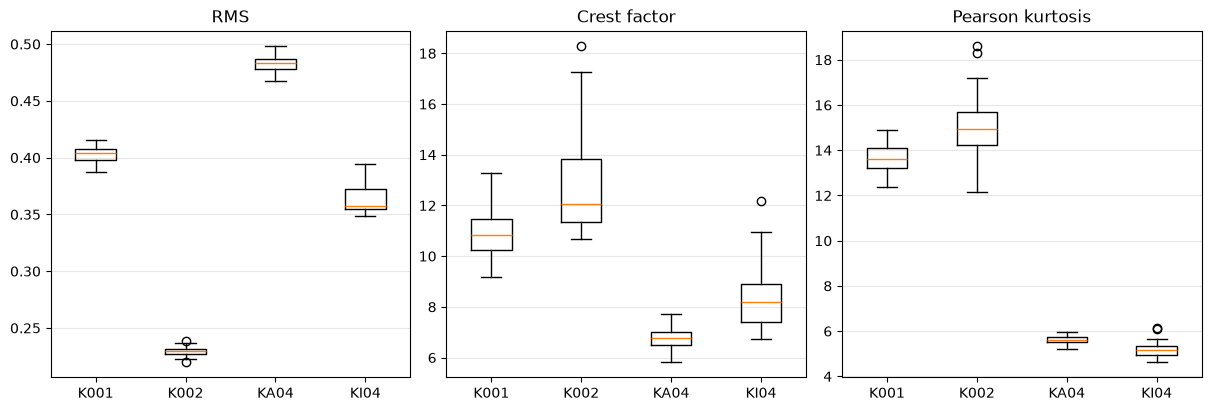

In [18]:
import matplotlib.pyplot as plt

columns = ["RMS", "Crest factor", "Pearson kurtosis"]
bearing_ids = sorted(same_setting["bearing_id"].unique())
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")

for ax, column in zip(axes, columns):
    data = [same_setting.loc[same_setting["bearing_id"].eq(b), column] for b in bearing_ids]
    ax.boxplot(data)
    ax.set_xticks(range(1, len(bearing_ids) + 1), bearing_ids)
    ax.set_title(column)
    ax.grid(axis="y", alpha=0.3)

plt.show()

In [19]:
settings = ["speed_code", "torq_code", "force_code"]
columns = ["RMS", "Crest factor", "Pearson kurtosis"]

summary = all_features.groupby(settings + ["bearing_id", "condition"])[columns].median()
summary.round(3)

RMS  Crest factor  \
speed_code torq_code force_code bearing_id condition                        
N09        M07       F10        K001       healthy    0.364        11.981   
                                K002       healthy    0.176        17.476   
                                KA04       faulty     0.214         8.311   
                                KI04       faulty     0.204        14.298   
N15        M01       F10        K001       healthy    0.401        11.125   
                                K002       healthy    0.235        13.435   
                                KA04       faulty     0.551         7.116   
                                KI04       faulty     0.357         8.419   
           M07       F04        K001       healthy    0.395        11.289   
                                K002       healthy    0.217        13.685   
                                KA04       faulty     0.438         5.782   
                                KI04       faulty     0.336         8.677   
                     F10        K001       healthy    0.404        10.845   
                                K002       healthy    0.230        12.072   
                                KA04       faulty     0.483         6.754   
                                KI04       faulty     0.358         8.173   

                                                      Pearson kurtosis  
speed_code torq_code force_code bearing_id condition                    
N09        M07       F10        K001       healthy              19.667  
                                K002       healthy              41.744  
                                KA04       faulty                8.457  
                                KI04       faulty               17.772  
N15        M01       F10        K001       healthy              14.311  
                                K002       healthy              15.452  
                                KA04       faulty                6.976  
                                KI04       faulty                5.336  
           M07       F04        K001       healthy              15.480  
                                K002       healthy              18.466  
                                KA04       faulty                4.891  
                                KI04       faulty                5.369  
                     F10        K001       healthy              13.627  
                                K002       healthy              14.936  
                                KA04       faulty                5.606  
                                KI04       faulty                5.166

In [20]:
share_columns = [
    column for column in all_features.columns
    if column.endswith("share (%)")
]

band_summary = all_features.groupby(
    settings + ["bearing_id", "condition"]
)[share_columns].median()

band_summary.round(2)

0-2000 Hz share (%)  \
speed_code torq_code force_code bearing_id condition                        
N09        M07       F10        K001       healthy                   6.57   
                                K002       healthy                   8.42   
                                KA04       faulty                   50.57   
                                KI04       faulty                    9.39   
N15        M01       F10        K001       healthy                   5.95   
                                K002       healthy                  23.18   
                                KA04       faulty                   32.94   
                                KI04       faulty                   12.73   
           M07       F04        K001       healthy                   6.32   
                                K002       healthy                  20.61   
                                KA04       faulty                   25.88   
                                KI04       faulty                    7.95   
                     F10        K001       healthy                   6.00   
                                K002       healthy                  24.30   
                                KA04       faulty                   33.65   
                                KI04       faulty                   12.52   

                                                      2000-5000 Hz share (%)  \
speed_code torq_code force_code bearing_id condition                           
N09        M07       F10        K001       healthy                     10.51   
                                K002       healthy                      9.92   
                                KA04       faulty                      11.71   
                                KI04       faulty                      18.38   
N15        M01       F10        K001       healthy                     14.59   
                                K002       healthy                     16.39   
                                KA04       faulty                      18.66   
                                KI04       faulty                      41.93   
           M07       F04        K001       healthy                     15.89   
                                K002       healthy                     20.68   
                                KA04       faulty                      25.44   
                                KI04       faulty                      40.14   
                     F10        K001       healthy                     14.58   
                                K002       healthy                     16.76   
                                KA04       faulty                      22.70   
                                KI04       faulty                      37.72   

                                                      5000-12000 Hz share (%)  \
speed_code torq_code force_code bearing_id condition                            
N09        M07       F10        K001       healthy                      22.76   
                                K002       healthy                      25.22   
                                KA04       faulty                       33.47   
                                KI04       faulty                       28.10   
N15        M01       F10        K001       healthy                      29.44   
                                K002       healthy                      29.57   
                                KA04       faulty                       47.61   
                                KI04       faulty                       31.60   
           M07       F04        K001       healthy                      24.53   
                                K002       healthy                      23.10   
                                KA04       faulty                       47.14   
                                KI04       faulty                       33.38   
                     F10        K001       healthy                      29.65   
           

In [21]:
columns = ["12000-32000 Hz power", "12000-32000 Hz share (%)"]

all_features.groupby(
    settings + ["bearing_id", "condition"]
)[columns].median().round(6)

12000-32000 Hz power  \
speed_code torq_code force_code bearing_id condition                         
N09        M07       F10        K001       healthy                0.079693   
                                K002       healthy                0.017275   
                                KA04       faulty                 0.002079   
                                KI04       faulty                 0.018314   
N15        M01       F10        K001       healthy                0.080605   
                                K002       healthy                0.016991   
                                KA04       faulty                 0.002533   
                                KI04       faulty                 0.017297   
           M07       F04        K001       healthy                0.083000   
                                K002       healthy                0.016874   
                                KA04       faulty                 0.002414   
                                KI04       faulty                 0.018929   
                     F10        K001       healthy                0.081493   
                                K002       healthy                0.016786   
                                KA04       faulty                 0.002517   
                                KI04       faulty                 0.019387   

                                                      12000-32000 Hz share (%)  
speed_code torq_code force_code bearing_id condition                            
N09        M07       F10        K001       healthy                   60.138007  
                                K002       healthy                   56.567060  
                                KA04       faulty                     4.450827  
                                KI04       faulty                    44.129486  
N15        M01       F10        K001       healthy                   50.123799  
                                K002       healthy                   30.601576  
                                KA04       faulty                     0.842179  
                                KI04       faulty                    13.586166  
           M07       F04        K001       healthy                   53.272864  
                                K002       healthy                   35.433354  
                                KA04       faulty                     1.249621  
                                KI04       faulty                    17.815698  
                     F10        K001       healthy                   49.761846  
                                K002       healthy                   31.983437  
                                KA04       faulty                     1.072887  
                                KI04       faulty                    15.166082

In [22]:
columns = ["Spectral centroid (Hz)", "Dominant frequency (Hz)"]

all_features.groupby(
    settings + ["bearing_id", "condition"]
)[columns].median().round(1)

Spectral centroid (Hz)  \
speed_code torq_code force_code bearing_id condition                           
N09        M07       F10        K001       healthy                   15556.9   
                                K002       healthy                   14873.2   
                                KA04       faulty                     4314.1   
                                KI04       faulty                    12627.9   
N15        M01       F10        K001       healthy                   13911.0   
                                K002       healthy                    9767.8   
                                KA04       faulty                     5063.5   
                                KI04       faulty                     6817.9   
           M07       F04        K001       healthy                   14312.5   
                                K002       healthy                   10534.2   
                                KA04       faulty                     5347.9   
                                KI04       faulty                     8010.1   
                     F10        K001       healthy                   13876.7   
                                K002       healthy                    9943.7   
                                KA04       faulty                     4669.4   
                                KI04       faulty                     7286.9   

                                                      Dominant frequency (Hz)  
speed_code torq_code force_code bearing_id condition                           
N09        M07       F10        K001       healthy                     3250.0  
                                K002       healthy                     5906.2  
                                KA04       faulty                       781.2  
                                KI04       faulty                      3382.8  
N15        M01       F10        K001       healthy                     3281.2  
                                K002       healthy                     1304.7  
                                KA04       faulty                       687.5  
                                KI04       faulty                      3414.1  
           M07       F04        K001       healthy                     3164.1  
                                K002       healthy                     1304.7  
                                KA04       faulty                       687.5  
                                KI04       faulty                      3253.9  
                     F10        K001       healthy                     5937.5  
                                K002       healthy                     1304.7  
                                KA04       faulty                       765.6  
                                KI04       faulty                      3414.1

In [23]:
validation_pairs = [
    ("K001", "KA04"),
    ("K001", "KI04"),
    ("K002", "KA04"),
    ("K002", "KI04")
]

for held_bearings in validation_pairs:
    mask = all_features["bearing_id"].isin(held_bearings)
    print("Validation bearings:", held_bearings)
    print("Training windows:", (~mask).sum(), "Validation windows:", mask.sum())

Validation bearings: ('K001', 'KA04')
Training windows: 566 Validation windows: 519
Validation bearings: ('K001', 'KI04')
Training windows: 585 Validation windows: 500
Validation bearings: ('K002', 'KA04')
Training windows: 500 Validation windows: 585
Validation bearings: ('K002', 'KI04')
Training windows: 519 Validation windows: 566


In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = all_features[["RMS"]]
y = all_features["condition"].map({"healthy": 0, "faulty": 1})
assert y.notna().all(), "Unknown condition label."

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)

In [25]:
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, balanced_accuracy_score

results = []
for held_bearings in validation_pairs:
    test = all_features["bearing_id"].isin(held_bearings)
    model = clone(baseline)
    model.fit(X.loc[~test], y.loc[~test])
    prediction = model.predict(X.loc[test])

    tn, fp, fn, tp = confusion_matrix(
        y.loc[test], prediction, labels=[0, 1]
    ).ravel()

    results.append({
        "Validation bearings": ", ".join(held_bearings),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(y.loc[test], prediction),
        "Fault recall (%)": 100 * tp / (tp + fn),
        "False alarms": fp,
        "Missed faults": fn
    })

rms_results = pd.DataFrame(results)
rms_results.round(2)

,Validation bearings,Balanced accuracy (%),Fault recall (%),False alarms,Missed faults
0,"K001, KA04",36.93,73.87,232,75
1,"K001, KI04",38.06,76.12,232,64
2,"K002, KA04",13.24,26.48,298,211
3,"K002, KI04",50.00,0.00,0,268


In [46]:
def evaluate(feature_columns, estimator=None, balance_xgb=False):
    X = all_features[feature_columns]
    results = []

    for held_bearings in validation_pairs:
        test = all_features["bearing_id"].isin(held_bearings)
        model = clone(baseline if estimator is None else estimator)
        if balance_xgb:
            train_y = y.loc[~test]
            model.set_params(scale_pos_weight=train_y.eq(0).sum() / train_y.eq(1).sum())
        model.fit(X.loc[~test], y.loc[~test])
        prediction = model.predict(X.loc[test])

        tn, fp, fn, tp = confusion_matrix(
            y.loc[test], prediction, labels=[0, 1]
        ).ravel()

        results.append({
            "Validation bearings": ", ".join(held_bearings),
            "Balanced accuracy (%)": 100 * balanced_accuracy_score(y.loc[test], prediction),
            "Fault recall (%)": 100 * tp / (tp + fn),
            "False alarms": fp,
            "Missed faults": fn
        })

    return pd.DataFrame(results)

In [47]:
feature_columns = all_features.columns.difference(registry.columns).tolist()
assert len(feature_columns) == 13, "Check the selected feature columns."

rms_results = evaluate(["RMS"])
multi_results = evaluate(feature_columns)

comparison = pd.concat(
    {"RMS only": rms_results, "All 13": multi_results},
    names=["Model"]
)
comparison.round(2)

Validation bearings  Balanced accuracy (%)  Fault recall (%)  \
Model                                                                     
RMS only 0          K001, KA04                  36.93             73.87   
         1          K001, KI04                  38.06             76.12   
         2          K002, KA04                  13.24             26.48   
         3          K002, KI04                  50.00              0.00   
All 13   0          K001, KA04                   0.00              0.00   
         1          K001, KI04                  50.00              0.00   
         2          K002, KA04                  50.17            100.00   
         3          K002, KI04                  87.89             76.12   

            False alarms  Missed faults  
Model                                    
RMS only 0           232             75  
         1           232             64  
         2           298            211  
         3             0            268  
All 13   0           232            287  
         1             0            268  
         2           297              0  
         3             1             64

In [48]:
keys = ["recording_id", "window_no", "bearing_id", "condition"]

expected = registry[keys].sort_values(keys).reset_index(drop=True)
actual = all_features[keys].sort_values(keys).reset_index(drop=True)

assert actual.equals(expected), "Feature metadata does not match the window registry."
assert y.equals(all_features["condition"].map({"healthy": 0, "faulty": 1})), "Model labels differ."

print("Metadata and model labels match.")

Metadata and model labels match.


In [49]:
check_records = all_features.drop_duplicates("bearing_id")

for _, record in check_records.iterrows():
    windows = np.load(project / record["window_file"])
    fs = float(record["nominal_fs_hz"])
    recalculated = extract_features(windows, fs)[feature_columns].to_numpy()

    stored = all_features[
        all_features["recording_id"].eq(record["recording_id"])
    ].sort_values("window_no")[feature_columns].to_numpy()

    assert stored.shape == recalculated.shape, record["recording_id"]
    assert np.allclose(stored, recalculated, rtol=1e-8, atol=1e-12), record["recording_id"]
    print(record["recording_id"], "— feature values match")

N09_M07_F10_K001_11 — feature values match
N09_M07_F10_K002_1 — feature values match
N09_M07_F10_KA04_1 — feature values match
N09_M07_F10_KI04_1 — feature values match


In [50]:
test = all_features["bearing_id"].isin(["K001", "KA04"])

failed_model = clone(baseline)
failed_model.fit(all_features.loc[~test, feature_columns], y.loc[~test])

weights = pd.Series(
    failed_model.named_steps["logisticregression"].coef_[0],
    index=feature_columns
)

weights.sort_values(key=abs, ascending=False).round(3)

Pearson kurtosis           -2.625
0-2000 Hz share (%)        -2.506
0-2000 Hz power            -1.613
2000-5000 Hz share (%)      1.251
5000-12000 Hz share (%)     1.209
12000-32000 Hz power        1.010
2000-5000 Hz power          0.411
Dominant frequency (Hz)     0.404
Crest factor               -0.346
RMS                         0.262
5000-12000 Hz power         0.261
12000-32000 Hz share (%)   -0.223
Spectral centroid (Hz)     -0.014
dtype: float64

In [51]:
scaled = failed_model.named_steps["standardscaler"].transform(
    all_features.loc[test, feature_columns]
)

contributions = pd.DataFrame(
    scaled, columns=feature_columns, index=all_features.index[test]
).mul(weights, axis=1)

contributions["bearing_id"] = all_features.loc[test, "bearing_id"]
print("Intercept:", failed_model.named_steps["logisticregression"].intercept_[0])

contributions.groupby("bearing_id").mean().round(2).T

Intercept: 0.9186895926802731


bearing_id,K001,KA04
0-2000 Hz power,0.40,-16.89
0-2000 Hz share (%),3.56,-8.16
12000-32000 Hz power,20.45,-5.20
12000-32000 Hz share (%),-0.36,0.47
2000-5000 Hz power,-0.04,0.35
2000-5000 Hz share (%),-1.21,-0.58
5000-12000 Hz power,0.34,1.16
5000-12000 Hz share (%),-0.64,4.47
Crest factor,0.10,0.49
Dominant frequency (Hz),0.36,-0.53


In [52]:
shape_results = evaluate(["Crest factor", "Pearson kurtosis"])

share_columns = [c for c in feature_columns if c.endswith("share (%)")]
share_results = evaluate(share_columns)

comparison = pd.concat({
    "RMS only": rms_results,
    "Waveform shape": shape_results,
    "Relative band power": share_results,
    "All 13": multi_results
}, names=["Model"])

comparison.round(2)

Validation bearings  Balanced accuracy (%)  \
Model                                                              
RMS only            0          K001, KA04                  36.93   
                    1          K001, KI04                  38.06   
                    2          K002, KA04                  13.24   
                    3          K002, KI04                  50.00   
Waveform shape      0          K001, KA04                  89.87   
                    1          K001, KI04                  86.58   
                    2          K002, KA04                  64.04   
                    3          K002, KI04                  88.06   
Relative band power 0          K001, KA04                  51.93   
                    1          K001, KI04                  50.00   
                    2          K002, KA04                  61.91   
                    3          K002, KI04                  88.06   
All 13              0          K001, KA04                   0.00   
                    1          K001, KI04                  50.00   
                    2          K002, KA04                  50.17   
                    3          K002, KI04                  87.89   

                       Fault recall (%)  False alarms  Missed faults  
Model                                                                 
RMS only            0             73.87           232             75  
                    1             76.12           232             64  
                    2             26.48           298            211  
                    3              0.00             0            268  
Waveform shape      0            100.00            47              0  
                    1             75.75             6             65  
                    2             60.63            97            113  
                    3             76.12             0             64  
Relative band power 0             72.82           160             78  
                    1              0.00             0            268  
                    2            100.00           227              0  
                    3             76.12             0             64  
All 13              0              0.00           232            287  
                    1              0.00             0            268  
                    2            100.00           297              0  
                    3             76.12             1             64

In [53]:
output = project / "reports/tables"
output.mkdir(parents=True, exist_ok=True)

comparison.rename_axis(index=["Model", "Fold"]).reset_index().to_csv(
    output / "development_model_comparison.csv", index=False
)

print("Saved development model comparison.")

Saved development model comparison.


In [54]:
shape_columns = ["Crest factor", "Pearson kurtosis"]
test = all_features["bearing_id"].isin(["K002", "KA04"])

model = clone(baseline)
model.fit(all_features.loc[~test, shape_columns], y.loc[~test])
prediction = model.predict(all_features.loc[test, shape_columns])

audit = all_features.loc[test, settings + ["condition"]].copy()
audit["Healthy windows"] = audit["condition"].eq("healthy")
audit["Fault windows"] = audit["condition"].eq("faulty")
audit["False alarms"] = audit["Healthy windows"] & (prediction == 1)
audit["Missed faults"] = audit["Fault windows"] & (prediction == 0)

errors = audit.groupby(settings)[
    ["Healthy windows", "Fault windows", "False alarms", "Missed faults"]
].sum()

errors["False alarm (%)"] = 100 * errors["False alarms"] / errors["Healthy windows"]
errors["Fault recall (%)"] = 100 * (1 - errors["Missed faults"] / errors["Fault windows"])
errors.round(2)

Healthy windows  Fault windows  False alarms  \
speed_code torq_code force_code                                                 
N09        M07       F10                      71             76             0   
N15        M01       F10                      72             67            44   
           M07       F04                      79             72            21   
                     F10                      76             72            32   

                                 Missed faults  False alarm (%)  \
speed_code torq_code force_code                                   
N09        M07       F10                    35             0.00   
N15        M01       F10                    37            61.11   
           M07       F04                    35            26.58   
                     F10                     6            42.11   

                                 Fault recall (%)  
speed_code torq_code force_code                    
N09        M07       F10                    53.95  
N15        M01       F10                    44.78  
           M07       F04                    51.39  
                     F10                    91.67

In [55]:
errors.to_csv(output / "waveform_shape_errors_by_setting.csv")
print("Saved error analysis.")

Saved error analysis.


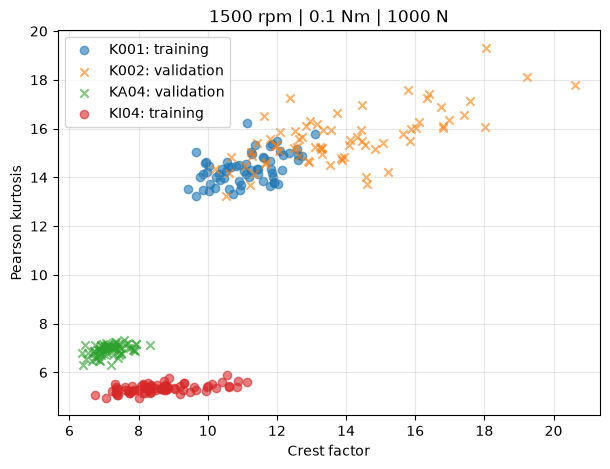

In [56]:
focus = all_features[
    all_features["speed_code"].eq("N15")
    & all_features["torq_code"].eq("M01")
    & all_features["force_code"].eq("F10")
]

fig, ax = plt.subplots(figsize=(7, 5))
for bearing, group in focus.groupby("bearing_id"):
    held_out = bearing in ["K002", "KA04"]
    ax.scatter(
        group["Crest factor"], group["Pearson kurtosis"],
        marker="x" if held_out else "o",
        label=f"{bearing}: {'validation' if held_out else 'training'}",
        alpha=0.6
    )

ax.set(xlabel="Crest factor", ylabel="Pearson kurtosis",
       title="1500 rpm | 0.1 Nm | 1000 N")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

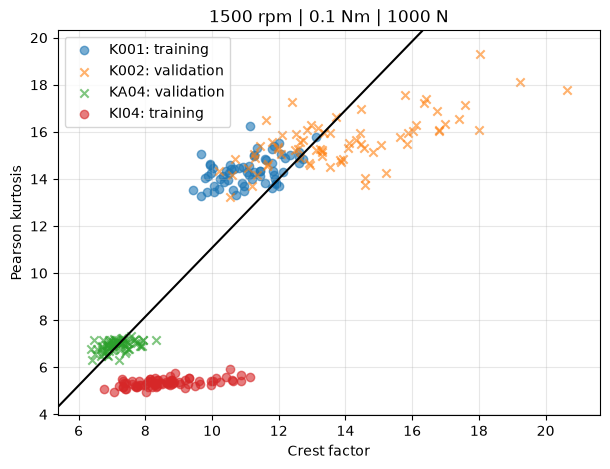

In [57]:
from sklearn.inspection import DecisionBoundaryDisplay
from IPython.display import display

shape_columns = ["Crest factor", "Pearson kurtosis"]
test = all_features["bearing_id"].isin(["K002", "KA04"])

shape_model = clone(baseline)
shape_model.fit(all_features.loc[~test, shape_columns], y.loc[~test])

DecisionBoundaryDisplay.from_estimator(
    shape_model, focus[shape_columns], ax=ax,
    response_method="decision_function",
    plot_method="contour", levels=[0], colors="black"
)
display(fig)

In [58]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42
)

In [59]:
forest_results = evaluate(shape_columns, forest)

model_comparison = pd.concat({
    "Logistic regression": shape_results,
    "Random Forest": forest_results
}, names=["Model"])

model_comparison.round(2)

Validation bearings  Balanced accuracy (%)  \
Model                                                              
Logistic regression 0          K001, KA04                  89.87   
                    1          K001, KI04                  86.58   
                    2          K002, KA04                  64.04   
                    3          K002, KI04                  88.06   
Random Forest       0          K001, KA04                  99.61   
                    1          K001, KI04                  87.63   
                    2          K002, KA04                  71.97   
                    3          K002, KI04                  88.06   

                       Fault recall (%)  False alarms  Missed faults  
Model                                                                 
Logistic regression 0            100.00            47              0  
                    1             75.75             6             65  
                    2             60.63            97            113  
                    3             76.12             0             64  
Random Forest       0             99.65             1              1  
                    1             76.12             2             64  
                    2             99.30           165              2  
                    3             76.12             0             64

In [67]:
def errors_by_setting(estimator, held_bearings, balance_xgb=False):
    test = all_features["bearing_id"].isin(held_bearings)
    X = all_features[shape_columns]
    model = clone(estimator)
    if balance_xgb:
        train_y = y.loc[~test]
        model.set_params(scale_pos_weight=train_y.eq(0).sum() / train_y.eq(1).sum())
    model.fit(X.loc[~test], y.loc[~test])
    prediction = model.predict(X.loc[test])

    audit = all_features.loc[test, settings].copy()
    audit["Healthy windows"] = y.loc[test].eq(0)
    audit["Fault windows"] = y.loc[test].eq(1)
    audit["False alarms"] = audit["Healthy windows"] & (prediction == 1)
    audit["Missed faults"] = audit["Fault windows"] & (prediction == 0)

    summary = audit.groupby(settings).sum()
    summary["False alarm (%)"] = 100 * summary["False alarms"] / summary["Healthy windows"]
    summary["Fault recall (%)"] = 100 * (1 - summary["Missed faults"] / summary["Fault windows"])
    return summary

In [61]:
rf_errors = errors_by_setting(forest, ["K002", "KA04"])
rf_errors.round(2)

Healthy windows  Fault windows  False alarms  \
speed_code torq_code force_code                                                 
N09        M07       F10                      71             76            71   
N15        M01       F10                      72             67            34   
           M07       F04                      79             72            40   
                     F10                      76             72            20   

                                 Missed faults  False alarm (%)  \
speed_code torq_code force_code                                   
N09        M07       F10                     2           100.00   
N15        M01       F10                     0            47.22   
           M07       F04                     0            50.63   
                     F10                     0            26.32   

                                 Fault recall (%)  
speed_code torq_code force_code                    
N09        M07       F10                    97.37  
N15        M01       F10                   100.00  
           M07       F04                   100.00  
                     F10                   100.00

In [62]:
output = project / "reports/tables"
output.mkdir(parents=True, exist_ok=True)

rf_errors.to_csv(output / "random_forest_errors_by_setting.csv")
model_comparison.rename_axis(index=["Model", "Fold"]).reset_index().to_csv(
    output / "waveform_model_comparison.csv", index=False
)

In [63]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [64]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100, max_depth=2, learning_rate=0.05,
    reg_lambda=5,
    objective="binary:logistic", eval_metric="logloss",
    tree_method="hist", random_state=42, n_jobs=2
)

In [65]:
xgb_results = evaluate(shape_columns, xgb_model, balance_xgb=True)

model_comparison = pd.concat({
    "Logistic regression": shape_results,
    "Random Forest": forest_results,
    "XGBoost": xgb_results
}, names=["Model"])

model_comparison.round(2)

Validation bearings  Balanced accuracy (%)  \
Model                                                              
Logistic regression 0          K001, KA04                  89.87   
                    1          K001, KI04                  86.58   
                    2          K002, KA04                  64.04   
                    3          K002, KI04                  88.06   
Random Forest       0          K001, KA04                  99.61   
                    1          K001, KI04                  87.63   
                    2          K002, KA04                  71.97   
                    3          K002, KI04                  88.06   
XGBoost             0          K001, KA04                  75.09   
                    1          K001, KI04                  88.06   
                    2          K002, KA04                  50.25   
                    3          K002, KI04                  87.89   

                       Fault recall (%)  False alarms  Missed faults  
Model                                                                 
Logistic regression 0            100.00            47              0  
                    1             75.75             6             65  
                    2             60.63            97            113  
                    3             76.12             0             64  
Random Forest       0             99.65             1              1  
                    1             76.12             2             64  
                    2             99.30           165              2  
                    3             76.12             0             64  
XGBoost             0             50.17             0            143  
                    1             76.12             0             64  
                    2             50.17           148            143  
                    3             76.12             1             64

In [66]:
model_comparison.rename_axis(index=["Model", "Fold"]).reset_index().to_csv(
    output / "waveform_model_comparison.csv", index=False
)

In [68]:
xgb_errors = errors_by_setting(
    xgb_model, ["K002", "KA04"], balance_xgb=True
)
xgb_errors.round(2)

Healthy windows  Fault windows  False alarms  \
speed_code torq_code force_code                                                 
N09        M07       F10                      71             76            65   
N15        M01       F10                      72             67            21   
           M07       F04                      79             72            49   
                     F10                      76             72            13   

                                 Missed faults  False alarm (%)  \
speed_code torq_code force_code                                   
N09        M07       F10                    76            91.55   
N15        M01       F10                    67            29.17   
           M07       F04                     0            62.03   
                     F10                     0            17.11   

                                 Fault recall (%)  
speed_code torq_code force_code                    
N09        M07       F10                      0.0  
N15        M01       F10                      0.0  
           M07       F04                    100.0  
                     F10                    100.0

In [69]:
xgb_errors.to_csv(output / "xgboost_errors_by_setting.csv")
print("Saved XGBoost error analysis.")

Saved XGBoost error analysis.
